# <center> Exploratory Data Analysis - Credit-Risk </center>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# CONFIGURAÇÕES DE VISUALIZAÇÃO
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12,5)

In [3]:
# CARREGANDO OS DADOS
df = pd.read_csv('../../data/raw/cs-training.csv', index_col=0)

In [4]:
# EXPLORAÇÃO INICIAL
print(f"Shape: {df.shape}")
print(f"\n--- Info ---")
print(df.info())
print(f"\n--- Description ---")
print(df.describe())

Shape: (150000, 11)

--- Info ---
<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    1

In [5]:
# DISTRIBUIÇÃO DO TARGET

target_counts = df['SeriousDlqin2yrs'].value_counts()
target_pct = df['SeriousDlqin2yrs'].value_counts(normalize=True) * 100

print("--- Contagem---")
print(target_counts)
print("\n--- Proporção (%) ---")
print(target_pct.round(2))

--- Contagem---
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

--- Proporção (%) ---
SeriousDlqin2yrs
0    93.32
1     6.68
Name: proportion, dtype: float64


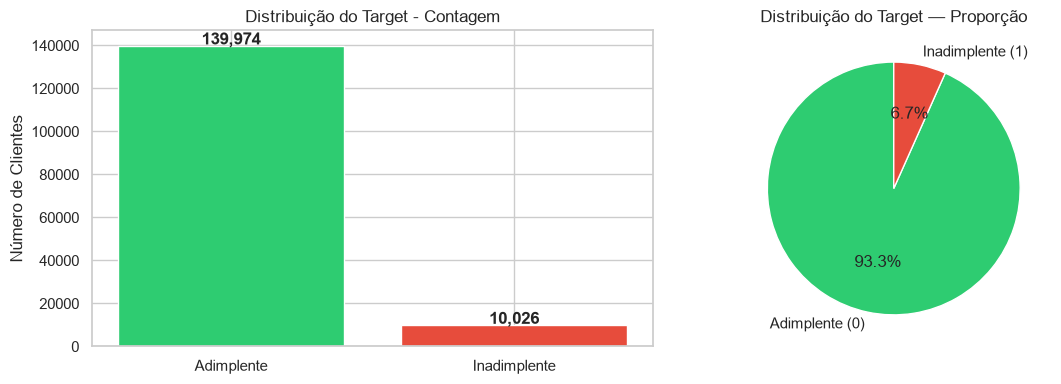

In [6]:
# VISUALIZANDO A DISTRIBUIÇÃO DO TARGET
fig, axes = plt.subplots(1,2, figsize=(12,4))

# GRÁFICO 1 - VALORES ABSOLUTOS
axes[0].bar(["Adimplente", "Inadimplente"], target_counts.values, color=["#2ecc71", "#e74c3c"])
axes[0].set_title("Distribuição do Target - Contagem")
axes[0].set_ylabel("Número de Clientes")
for i, v in enumerate(target_counts.values):
    axes[0].text(i,v + 500, f"{v:,}", ha="center", fontweight="bold")
    
# GRÁFICO 2 - PERCENTUAL
axes[1].pie(target_counts.values,
            labels=["Adimplente (0)", "Inadimplente (1)"],
            colors=["#2ecc71", "#e74c3c"],
            autopct="%1.1f%%",
            startangle=90)
axes[1].set_title("Distribuição do Target — Proporção")

plt.tight_layout()
plt.savefig('../../reports/target_distribution.png', dpi = 500, bbox_inches='tight')
plt.show()

In [7]:
# AVALIAÇÃO DOS VALORES FALTANTES

missing = pd.DataFrame({
    "total_missing": df.isnull().sum(),
    "pct_missing": (df.isnull().sum() / len(df) * 100).round(2)
}).query("total_missing > 0").sort_values("pct_missing", ascending=False)
print(missing)

                    total_missing  pct_missing
MonthlyIncome               29731        19.82
NumberOfDependents           3924         2.62


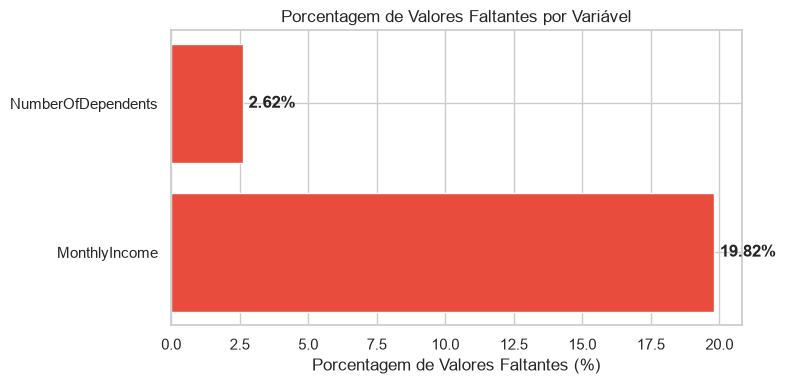

In [8]:
# VISUALIZAÇÃO DOS VALORES FALTANTES
fig, ax = plt.subplots(figsize=(8,4))
ax.barh(missing.index, missing['pct_missing'], color="#e74c3c")
ax.set_xlabel("Porcentagem de Valores Faltantes (%)")
ax.set_title("Porcentagem de Valores Faltantes por Variável")
for i, v in enumerate(missing['pct_missing']):
    ax.text(v + 0.2, i, f"{v:.2f}%", va="center", fontweight="bold")
plt.tight_layout()
plt.savefig('../../reports/missing_values.png', dpi = 150, bbox_inches='tight')
plt.show()

In [9]:
# AVALIANDO A ALEATORIEDADE DOS VALORES FALTANTES
# comparando renda mensal com inadimplência grave

tem_renda = df[df['MonthlyIncome'].notna()]["SeriousDlqin2yrs"].mean()
sem_renda = df[df['MonthlyIncome'].isna()]["SeriousDlqin2yrs"].mean()

print(f"\n Taxa de inadimplência para clientes com renda mensal: {tem_renda:.2f}")
print(f"\n Taxa de inadimplência para clientes sem renda mensal: {sem_renda:.2f}")
print(f"\nDiferença: {abs(tem_renda - sem_renda):.2%}")


 Taxa de inadimplência para clientes com renda mensal: 0.07

 Taxa de inadimplência para clientes sem renda mensal: 0.06

Diferença: 1.33%


In [10]:
# CRIANDO UMA FEATURE BINÁRIA PARA RENDA FALTANTE
df["flag_missing_income"] = df["MonthlyIncome"].isna().astype(int)
df["flag_missing_dependents"] = df["NumberOfDependents"].isna().astype(int)

In [11]:
# IMPUTAÇÃO PELA MEDIANA PARA RENDA MENSAL E NÚMERO DE DEPENDENTES
df['MonthlyIncome'] = df['MonthlyIncome'].fillna(df['MonthlyIncome'].median())
df['NumberOfDependents'] = df['NumberOfDependents'].fillna(df['NumberOfDependents'].median())

In [12]:
# VERIFICANDO OS DADOS APÓS A IMPUTAÇÃO
print(df.isnull().sum().sum(), "nulos restantes")

0 nulos restantes


In [13]:
print(df[['flag_missing_income', 'flag_missing_dependents']].value_counts())

flag_missing_income  flag_missing_dependents
0                    0                          120269
1                    0                           25807
                     1                            3924
Name: count, dtype: int64


In [14]:
# DISTRIBUIÇÃO DAS FEATURES E ANÁLISE DE OUTLIERS
features_numericas = ["RevolvingUtilizationOfUnsecuredLines", "age", "DebtRatio",
    "MonthlyIncome", "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines", "NumberOfDependents"]

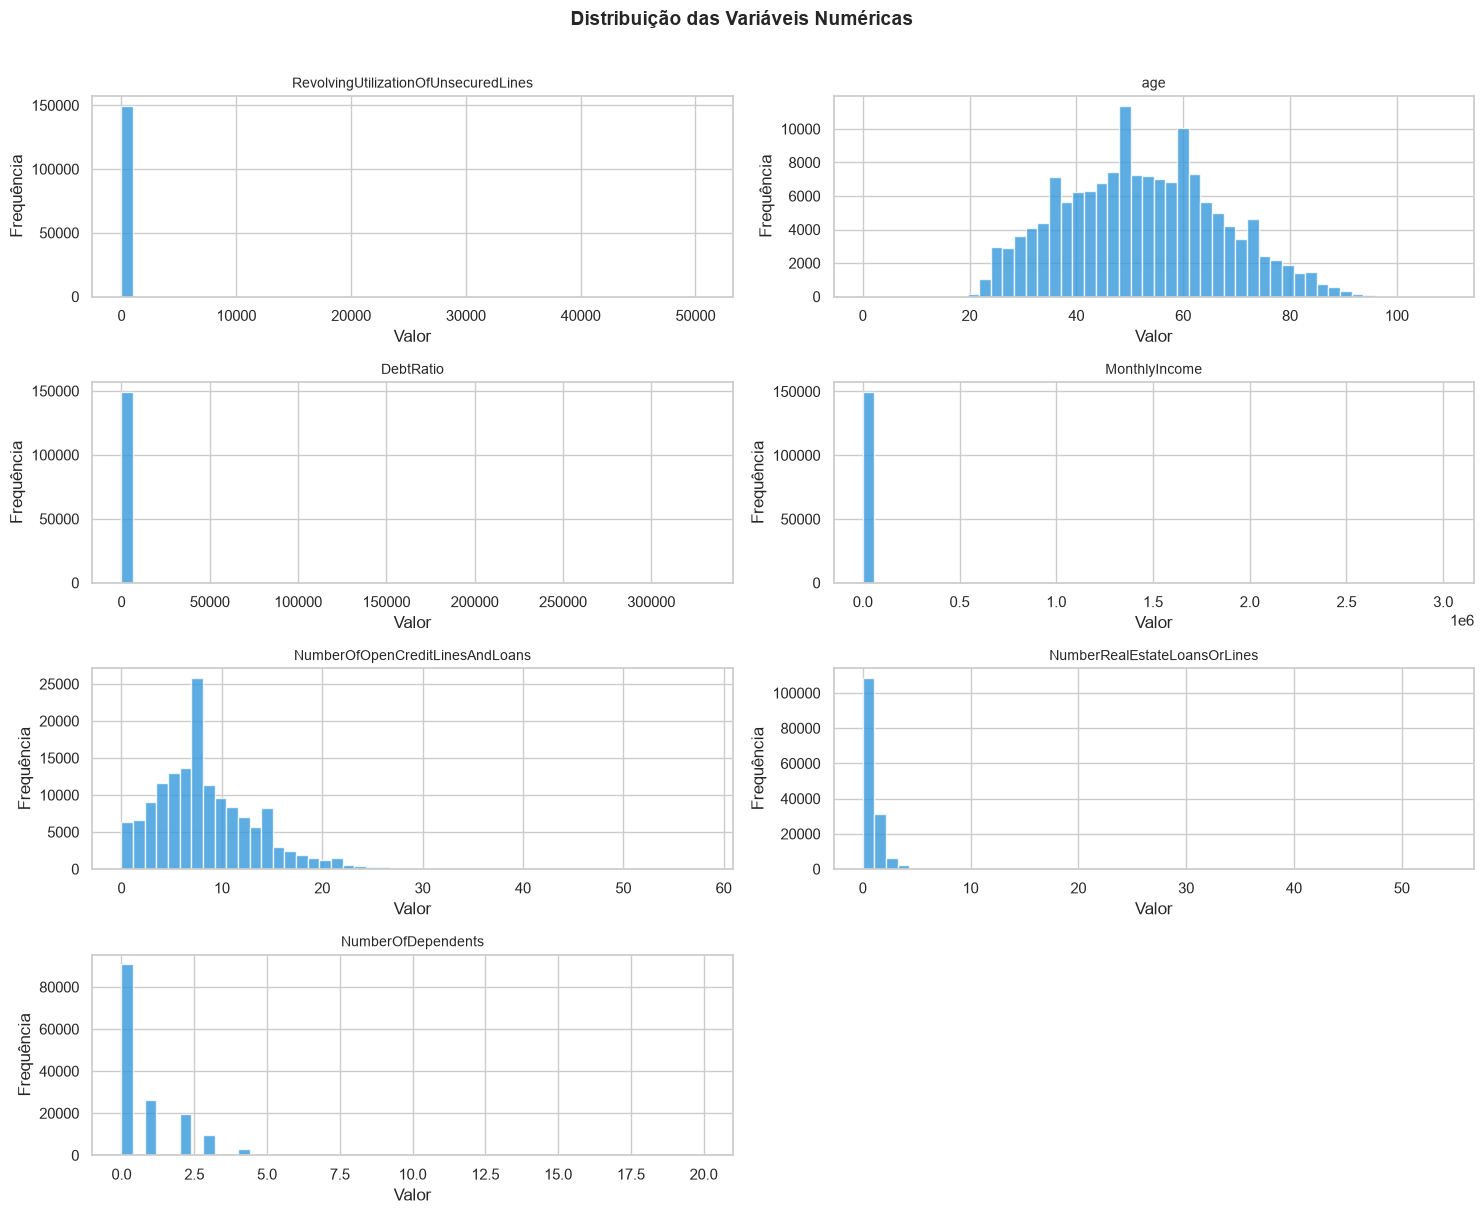

In [15]:
fig, axes = plt.subplots(4,2, figsize=(15,12))
axes = axes.flatten()

for i, col in enumerate(features_numericas):
    axes[i].hist(df[col], bins=50, color="#3498db", edgecolor="white", alpha=0.8)
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("Valor")
    axes[i].set_ylabel("Frequência")
    
# OCULTANDO SUBPLOT VAZIO
for j in range(i+1, len(axes)):
    axes[j].set_visible(False)
    
plt.suptitle("Distribuição das Variáveis Numéricas", fontsize=14, fontweight="bold", y= 1.01)
plt.tight_layout()
plt.savefig('../../reports/numeric_distributions.png', dpi = 150, bbox_inches='tight')
plt.show()

In [16]:
# INVESTIGAÇÃO DE OUTLIERS

print("=== RevolvingUtilization ===")
print(f"% acima de 1.0: {(df['RevolvingUtilizationOfUnsecuredLines'] > 1).mean():.2%}")
print(f"Máximo: {df['RevolvingUtilizationOfUnsecuredLines'].max():.2f}")

print("\n=== Age ===")
print(f"Clientes com age == 0: {(df['age'] == 0).sum()}")
print(f"Clientes com age > 90: {(df['age'] > 90).sum()}")

print("\n=== DebtRatio ===")
print(f"% acima de 1.0: {(df['DebtRatio'] > 1).mean():.2%}")
print(f"% acima de 100: {(df['DebtRatio'] > 100).mean():.2%}")

print("\n=== MonthlyIncome ===")
print(f"Máximo: {df['MonthlyIncome'].max():,.0f}")
print(f"Percentil 99%: {df['MonthlyIncome'].quantile(0.99):,.0f}")
print(f"Percentil 95%: {df['MonthlyIncome'].quantile(0.95):,.0f}")

=== RevolvingUtilization ===
% acima de 1.0: 2.21%
Máximo: 50708.00

=== Age ===
Clientes com age == 0: 1
Clientes com age > 90: 489

=== DebtRatio ===
% acima de 1.0: 23.42%
% acima de 100: 16.25%

=== MonthlyIncome ===
Máximo: 3,008,750
Percentil 99%: 23,000
Percentil 95%: 13,500


In [17]:
# TRATANDO OUTLIERS

# REMOVENDO REGISTROS COM AGE == 0
print(f"Registros antes: {len(df)}")
df = df[df['age'] != 0].copy()
print(f"Registros depois: {len(df)}")

Registros antes: 150000
Registros depois: 149999


In [18]:
# INVESTIGANDO AGE > 90 ANTES DE DECIDIR REMOVER
print("\n--- Clientes com age > 90 ---")
print(df[df['age']>90]['age'].value_counts().sort_index())
print(f"Taxa inadimplencia age > 90: {df[df['age']>90]['SeriousDlqin2yrs'].mean():.2%}")
print(f"Taxa inadimplencia geral: {df['SeriousDlqin2yrs'].mean():.2%}")


--- Clientes com age > 90 ---
age
91     154
92      93
93      87
94      47
95      45
96      18
97      17
98       6
99       9
101      3
102      3
103      3
105      1
107      1
109      2
Name: count, dtype: int64
Taxa inadimplencia age > 90: 2.25%
Taxa inadimplencia geral: 6.68%


In [19]:
# WINSORIZAÇÃO

colunas_winsor = {"RevolvingUtilizationOfUnsecuredLines": 0.99, "DebtRatio": 0.99, "MonthlyIncome": 0.99}

for col, percentil in colunas_winsor.items():
    p = df[col].quantile(percentil)
    antes = df[col].max()
    df[col] = df[col].clip(upper=p)
    print(f"{col}: max {antes:,.0f} -> {df[col].max():,.0f}")

RevolvingUtilizationOfUnsecuredLines: max 50,708 -> 1
DebtRatio: max 329,664 -> 4,979
MonthlyIncome: max 3,008,750 -> 23,000


In [20]:
# VERIFICAÇÃO FINAL
print('\n--- Estatisticas após tratamento de outliers ---')
print(df[list(colunas_winsor.keys())].describe().round(2))


--- Estatisticas após tratamento de outliers ---
       RevolvingUtilizationOfUnsecuredLines  DebtRatio  MonthlyIncome
count                             149999.00  149999.00      149999.00
mean                                   0.32     316.55        6142.45
std                                    0.35     906.97        3835.69
min                                    0.00       0.00           0.00
25%                                    0.03       0.18        3903.00
50%                                    0.15       0.37        5400.00
75%                                    0.56       0.87        7400.00
max                                    1.09    4979.08       23000.00


In [21]:
# TRATANDO OUTLIERS DE DEBT RATIO COM P95

print("Percentis de DebtRatio:")
for p in [0.90, 0.95, 0.97, 0.99]:
    print(f" p{int(p*100)}: {df['DebtRatio'].quantile(p):.2f}")


Percentis de DebtRatio:
 p90: 1267.00
 p95: 2449.00
 p97: 3225.00
 p99: 4979.00


In [22]:
# WINSORIZANDO DEBT RATIO NO P95
p95_debt = df['DebtRatio'].quantile(0.95)
df['DebtRatio'] = df['DebtRatio'].clip(upper=p95_debt)
print(f"\nDebtRatio apos p95: max = {df['DebtRatio'].max():,.2f}")
print(f"Media apos correcao: {df['DebtRatio'].mean():.2f}")


DebtRatio apos p95: max = 2,449.00
Media apos correcao: 254.64


In [23]:
# INVESTIGAÇÃO MAIS APROFUNDADA DE DEBT RATIO
print("Distribuição de DebtRatio por faixas:")
faixas = [0, 0.5, 1, 2, 5, 10, 100, 1000, 10000]
print(pd.cut(df["DebtRatio"], bins=faixas).value_counts().sort_index())

Distribuição de DebtRatio por faixas:
DebtRatio
(0.0, 0.5]           89594
(0.5, 1.0]           21155
(1.0, 2.0]            4092
(2.0, 5.0]            1399
(5.0, 10.0]            769
(10.0, 100.0]         4497
(100.0, 1000.0]       7488
(1000.0, 10000.0]    16892
Name: count, dtype: int64


In [24]:
# AVALIANDO AS FAIXAS
plausivel = (df["DebtRatio"] < 2).mean()
print(f"\n% com DebtRatio < 2 (plausível): {plausivel:.2%}")
print(f"% com DebtRatio >= 2 (suspeito): {(1-plausivel):.2%}")


% com DebtRatio < 2 (plausível): 79.19%
% com DebtRatio >= 2 (suspeito): 20.81%


In [25]:
# INADIMPLÊNCIA POR FAIXAS DE DEBT RATIO
df["debt_faixa"] = pd.cut(df["DebtRatio"], bins=[0, 1, 2, 10, 100, 99999],
                           labels=["0-1", "1-2", "2-10", "10-100", "100+"])
print("\nTaxa inadimplência por faixa de DebtRatio:")
print(df.groupby("debt_faixa", observed=True)["SeriousDlqin2yrs"].agg(["mean", "count"]).round(3))


Taxa inadimplência por faixa de DebtRatio:
             mean   count
debt_faixa               
0-1         0.067  110749
1-2         0.132    4092
2-10        0.066    2168
10-100      0.044    4497
100+        0.058   24380


In [26]:
# REMOVENDO COLUNAS TEMPORÁRIAS
df = df.drop(columns=["debt_faixa"])

In [27]:
# TESTANDO A HIPÓTESE DE QUE MONTHLY INCOME = 0 OU AUSENTE ESTÁ ASSOCIADO A DEBT RATIO ALTO
print("=== Investigando origem do DebtRatio alto ===")

# Cruzar DebtRatio alto com flag de missing income
alto = df[df["DebtRatio"] > 100]
baixo = df[df["DebtRatio"] <= 100]

print(f"DebtRatio > 100 — % com flag_missing_income=1: {alto['flag_missing_income'].mean():.2%}")
print(f"DebtRatio <= 100 — % com flag_missing_income=1: {baixo['flag_missing_income'].mean():.2%}")

# Distribuição de MonthlyIncome para quem tem DebtRatio > 100
print(f"\nDebtRatio > 100 — MonthlyIncome médio: {alto['MonthlyIncome'].mean():,.0f}")
print(f"DebtRatio <= 100 — MonthlyIncome médio: {baixo['MonthlyIncome'].mean():,.0f}")

=== Investigando origem do DebtRatio alto ===
DebtRatio > 100 — % com flag_missing_income=1: 93.08%
DebtRatio <= 100 — % com flag_missing_income=1: 5.60%

DebtRatio > 100 — MonthlyIncome médio: 5,026
DebtRatio <= 100 — MonthlyIncome médio: 6,359


In [28]:
# ── OBSERVAÇÃO CRÍTICA DA EDA ──────────────────────────────────
# 93% dos registros com DebtRatio > 100 correspondem a clientes sem renda informada (flag_missing_income = 1).
#
# Hipótese confirmada: DebtRatio foi calculado na origem como dívida / MonthlyIncome. Quando MonthlyIncome era nulo (zero ou ausente), o resultado gerou valores absurdos.
#
# Consequência: DebtRatio não é confiável para ~16k registros.
# Estratégia: winsorizar pelo p99 do subconjunto plausível (< 2),
# isolando o limite real do dado corrompido.
# ────────────────────────────────────────────────────────────

In [29]:
# DECISÃO FINAL — WINSORIZAÇÃO NO p99
# Usamos apenas quem tem DebtRatio < 2 para calcular o limite real
p99_plausivel = df[df["DebtRatio"] < 2]["DebtRatio"].quantile(0.99)
print(f"\nP99 do grupo plausível (DebtRatio < 2): {p99_plausivel:.4f}")

df["DebtRatio"] = df["DebtRatio"].clip(upper=p99_plausivel)
print(f"DebtRatio após winsorização contextual: max = {df['DebtRatio'].max():.4f}")
print(f"Média após correção: {df['DebtRatio'].mean():.4f}")


P99 do grupo plausível (DebtRatio < 2): 1.4024


DebtRatio após winsorização contextual: max = 1.4024
Média após correção: 0.5562


In [30]:
#"O DebtRatio está corrompido para clientes sem renda informada. 
# Mas já criamos flag_missing_income = 1 para identificar exatamente esse grupo. 
# O modelo pode aprender que quando flag_missing_income = 1, o DebtRatio não é confiável
# e usar as outras features para tomar a decisão."

In [31]:
# VERIFICAÇÃO FINAL DO DATASET
print("--- Estado atual do dataset ---")
print(f"Registros: {len(df):,}")
print(f"Features: {df.shape[1]}")
print(f"Nulos restantes: {df.isnull().sum().sum()}")
print(f"\nFeatures Disponiveis:")
print(df.columns.tolist())

--- Estado atual do dataset ---
Registros: 149,999
Features: 13
Nulos restantes: 0

Features Disponiveis:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'flag_missing_income', 'flag_missing_dependents']


In [32]:
# CORRELAÇÕES COM O TARGET
correlacoes = df.corr()['SeriousDlqin2yrs'].drop('SeriousDlqin2yrs').sort_values(ascending=False)
print("--- Correlações com o Target ---")
print(correlacoes.round(4))

--- Correlações com o Target ---
RevolvingUtilizationOfUnsecuredLines    0.2808
NumberOfTime30-59DaysPastDueNotWorse    0.1256
NumberOfTimes90DaysLate                 0.1172
NumberOfTime60-89DaysPastDueNotWorse    0.1023
NumberOfDependents                      0.0469
DebtRatio                               0.0131
NumberRealEstateLoansOrLines           -0.0070
flag_missing_dependents                -0.0139
flag_missing_income                    -0.0213
NumberOfOpenCreditLinesAndLoans        -0.0297
MonthlyIncome                          -0.0498
age                                    -0.1154
Name: SeriousDlqin2yrs, dtype: float64


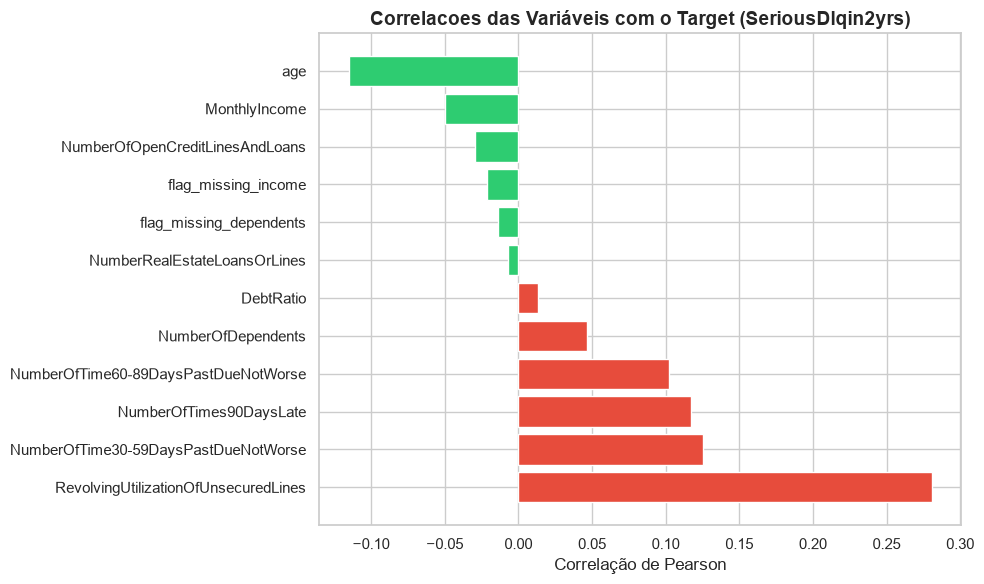

In [33]:
# VISUALIZANDO AS CORRELAÇÕES
fig, ax = plt.subplots(figsize=(10,6))
cores = ["#e74c3c" if v > 0 else "#2ecc71" for v in correlacoes.values]
ax.barh(correlacoes.index, correlacoes.values, color=cores)
ax.set_title("Correlacoes das Variáveis com o Target (SeriousDlqin2yrs)", fontsize=14, fontweight="bold")
ax.set_xlabel("Correlação de Pearson")
plt.tight_layout()
plt.savefig('../../reports/target_correlations.png', dpi = 150, bbox_inches='tight')
plt.show()

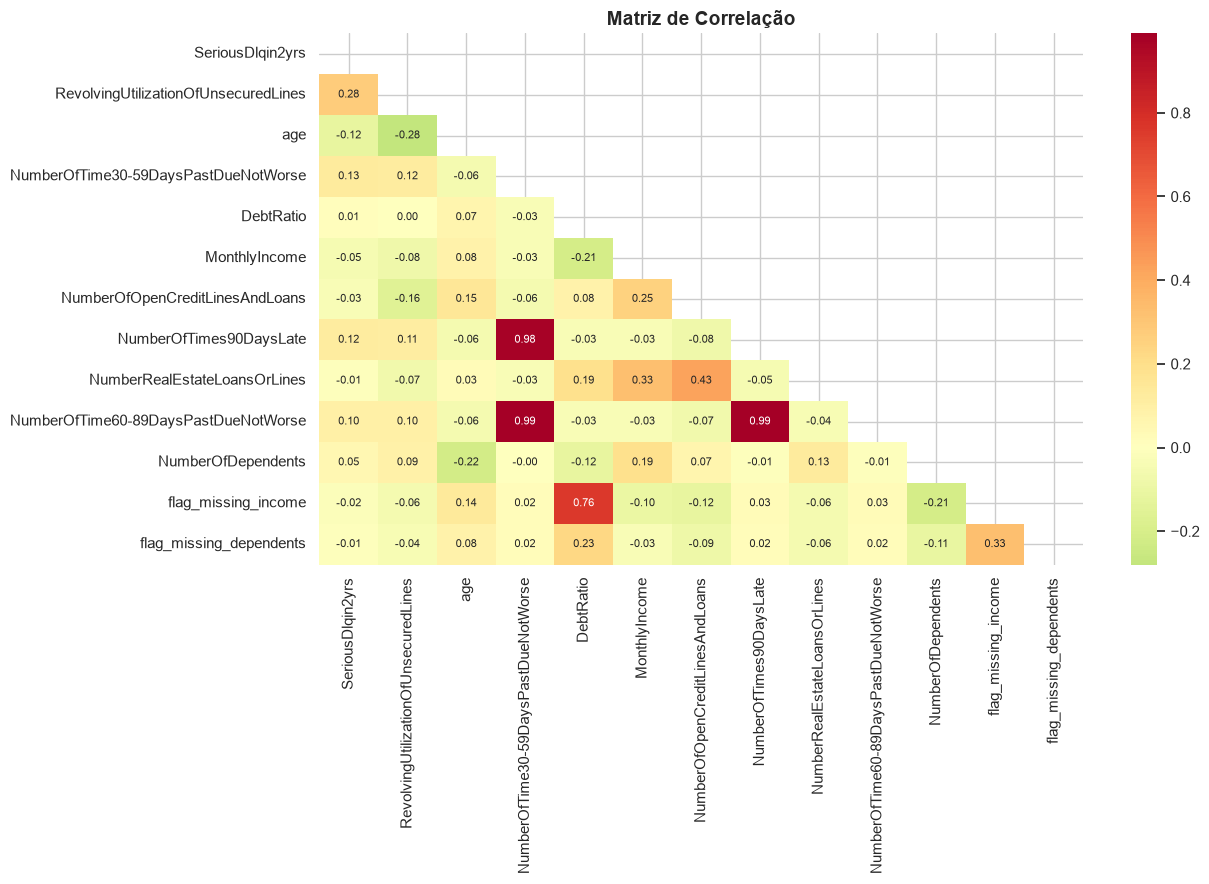

In [34]:
# MATRIZ DE CORRELAÇÃO
fig, ax = plt.subplots(figsize=(13,9))
mask = np.triu(np.ones_like(df.corr(), dtype=bool))
sns.heatmap(df.corr().round(2),
            mask = mask,
            annot=True,
            fmt=".2f",
            cmap="RdYlGn_r",
            center=0,
            ax=ax,
            annot_kws={"size":8})
ax.set_title("Matriz de Correlação", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig('../../reports/correlation_matrix.png', dpi = 150, bbox_inches='tight')
plt.show()

In [35]:
# TAXA DE INADIMPLÊNCIA POR FAIXA ETÁRIA
df["age_faixa"] = pd.cut(df["age"],
                          bins=[0, 25, 35, 45, 55, 65, 110],
                          labels=["<25", "25-35", "35-45", "45-55", "55-65", "65+"])

print("\n=== Taxa de inadimplência por faixa etária ===")
print(df.groupby("age_faixa", observed=True)["SeriousDlqin2yrs"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "taxa_inadimplencia", "count": "clientes"})
        .round(3))

df = df.drop(columns=["age_faixa"])


=== Taxa de inadimplência por faixa etária ===
           taxa_inadimplencia  clientes
age_faixa                              
<25                     0.112      3027
25-35                   0.111     18458
35-45                   0.088     29819
45-55                   0.076     36690
55-65                   0.046     33406
65+                     0.024     28599


In [36]:
# FUNÇÃO DE INFORMATION VALUE
def calcular_iv(df, feature, target, bins=10):
    df_temp = df[[feature, target]].copy()
    
    # Discretizar features contínuas
    if df_temp[feature].nunique() > 10:
        df_temp["bin"] = pd.qcut(df_temp[feature], q=bins, duplicates="drop")
    else:
        df_temp["bin"] = df_temp[feature]
    
    # Calcular WoE e IV por bin
    total_events = df_temp[target].sum()
    total_non_events = len(df_temp) - total_events
    
    iv_table = df_temp.groupby("bin", observed=True)[target].agg(
        events="sum",
        total="count"
    )
    iv_table["non_events"] = iv_table["total"] - iv_table["events"]
    iv_table["pct_events"] = iv_table["events"] / total_events
    iv_table["pct_non_events"] = iv_table["non_events"] / total_non_events
    
    # Evitar log(0)
    iv_table = iv_table[(iv_table["pct_events"] > 0) & (iv_table["pct_non_events"] > 0)]
    
    iv_table["woe"] = np.log(iv_table["pct_events"] / iv_table["pct_non_events"])
    iv_table["iv"] = (iv_table["pct_events"] - iv_table["pct_non_events"]) * iv_table["woe"]
    
    return iv_table["iv"].sum()


In [37]:
# CALCULANDO O IV DE TODAS AS FEATURES
features = [c for c in df.columns if c != "SeriousDlqin2yrs"]
iv_scores = {f: calcular_iv(df, f, "SeriousDlqin2yrs") for f in features}
iv_df = pd.DataFrame.from_dict(iv_scores, orient="index", columns=["IV"])\
          .sort_values("IV", ascending=False)

print("=== Information Value por Feature ===")
print(iv_df.round(4))

=== Information Value por Feature ===
                                          IV
RevolvingUtilizationOfUnsecuredLines  1.1134
NumberOfTime30-59DaysPastDueNotWorse  0.4718
age                                   0.2592
MonthlyIncome                         0.0670
NumberOfOpenCreditLinesAndLoans       0.0669
DebtRatio                             0.0253
NumberOfDependents                    0.0250
NumberRealEstateLoansOrLines          0.0121
flag_missing_income                   0.0077
flag_missing_dependents               0.0037
NumberOfTimes90DaysLate               0.0000
NumberOfTime60-89DaysPastDueNotWorse  0.0000


In [38]:
# FUNÇÃO DE CLASSIFICAÇÃO DO IV
def classificar_iv(iv):
    if iv < 0.02: return "Fraco"
    elif iv < 0.1: return "Médio"
    elif iv < 0.3: return "Forte"
    else: return "Suspeito (possível leakage)"


In [39]:
# CLASSIFICANDO AS FEATURES PELO IV
iv_df["classificacao"] = iv_df["IV"].apply(classificar_iv)
print("\n=== Classificação ===")
print(iv_df)


=== Classificação ===
                                            IV                classificacao
RevolvingUtilizationOfUnsecuredLines  1.113441  Suspeito (possível leakage)
NumberOfTime30-59DaysPastDueNotWorse  0.471829  Suspeito (possível leakage)
age                                   0.259169                        Forte
MonthlyIncome                         0.066954                        Médio
NumberOfOpenCreditLinesAndLoans       0.066889                        Médio
DebtRatio                             0.025345                        Médio
NumberOfDependents                    0.024968                        Médio
NumberRealEstateLoansOrLines          0.012089                        Fraco
flag_missing_income                   0.007741                        Fraco
flag_missing_dependents               0.003682                        Fraco
NumberOfTimes90DaysLate               0.000000                        Fraco
NumberOfTime60-89DaysPastDueNotWorse  0.000000                   

In [40]:
# INVESTIGANDO O IV DE REVOLVING UTILIZATION
print("=== RevolvingUtilization por faixa ===")
df["revolving_faixa"] = pd.qcut(
    df["RevolvingUtilizationOfUnsecuredLines"], q=10, duplicates="drop"
)
print(df.groupby("revolving_faixa", observed=True)["SeriousDlqin2yrs"]
        .agg(["mean", "count"])
        .rename(columns={"mean": "taxa_inadimplencia", "count": "clientes"})
        .round(3))
df = df.drop(columns=["revolving_faixa"])

=== RevolvingUtilization por faixa ===
                   taxa_inadimplencia  clientes
revolving_faixa                                
(-0.001, 0.00297]               0.025     15000
(0.00297, 0.0192]               0.014     15000
(0.0192, 0.0435]                0.014     15000
(0.0435, 0.0832]                0.019     15000
(0.0832, 0.154]                 0.024     15000
(0.154, 0.271]                  0.035     14999
(0.271, 0.445]                  0.052     15000
(0.445, 0.699]                  0.088     15000
(0.699, 0.981]                  0.166     15000
(0.981, 1.093]                  0.232     15000


In [41]:
# INVESTIGANDO FEATURES COM IV = 0
print("\n=== Distribuição NumberOfTimes90DaysLate ===")
print(df["NumberOfTimes90DaysLate"].value_counts().sort_index().head(10))
print(f"% com valor 0: {(df['NumberOfTimes90DaysLate'] == 0).mean():.2%}")

print("\n=== Distribuição NumberOfTime60-89DaysPastDueNotWorse ===")
print(df["NumberOfTime60-89DaysPastDueNotWorse"].value_counts().sort_index().head(10))
print(f"% com valor 0: {(df['NumberOfTime60-89DaysPastDueNotWorse'] == 0).mean():.2%}")


=== Distribuição NumberOfTimes90DaysLate ===
NumberOfTimes90DaysLate
0    141661
1      5243
2      1555
3       667
4       291
5       131
6        80
7        38
8        21
9        19
Name: count, dtype: int64
% com valor 0: 94.44%

=== Distribuição NumberOfTime60-89DaysPastDueNotWorse ===
NumberOfTime60-89DaysPastDueNotWorse
0    142395
1      5731
2      1118
3       318
4       105
5        34
6        16
7         9
8         2
9         1
Name: count, dtype: int64
% com valor 0: 94.93%


In [42]:
# RECALCULANDO O IV APÓS A INVESTIGAÇÃO (MENOS FAIXAS)
for col in ["NumberOfTimes90DaysLate", "NumberOfTime60-89DaysPastDueNotWorse",
            "NumberOfTime30-59DaysPastDueNotWorse"]:
    iv = calcular_iv(df, col, "SeriousDlqin2yrs", bins=5)
    print(f"\nIV recalculado ({col}): {iv:.4f}")


IV recalculado (NumberOfTimes90DaysLate): 0.0000

IV recalculado (NumberOfTime60-89DaysPastDueNotWorse): 0.0000

IV recalculado (NumberOfTime30-59DaysPastDueNotWorse): 0.0000


In [43]:
#A relação é monotônica e gradual — quanto maior a utilização do crédito rotativo, maior a inadimplência. 
# Sem saltos abruptos, sem comportamento anômalo.
# Conclusão: não é leakage. O IV alto (1.11) reflete que essa feature é genuinamente muito preditiva 
# e faz sentido de negócio. 
# Quem usa 98% do limite do cartão tem risco real de inadimplir. 
# O IV > 0.3 como "suspeito" é uma heurística conservadora, não uma regra absoluta.

In [44]:
# RECALCULANDO O IV PARA FEATURES COM DISTRIBUIÇÕES EXTREMAS
def iv_contagem(df, col, target):
    """IV específico para variáveis de contagem com alta concentração em 0"""
    df_temp = df[[col, target]].copy()
    
    # Bins de negócio: 0, 1, 2, 3+
    df_temp["bin"] = pd.cut(
        df_temp[col],
        bins=[-1, 0, 1, 2, 999],
        labels=["0", "1", "2", "3+"]
    )
    
    total_events = df_temp[target].sum()
    total_non_events = len(df_temp) - total_events
    
    iv_table = df_temp.groupby("bin", observed=True)[target].agg(
        events="sum", total="count"
    )
    iv_table["non_events"] = iv_table["total"] - iv_table["events"]
    iv_table["pct_events"] = iv_table["events"] / total_events
    iv_table["pct_non_events"] = iv_table["non_events"] / total_non_events
    iv_table = iv_table[
        (iv_table["pct_events"] > 0) & (iv_table["pct_non_events"] > 0)
    ]
    iv_table["woe"] = np.log(
        iv_table["pct_events"] / iv_table["pct_non_events"]
    )
    iv_table["iv"] = (
        (iv_table["pct_events"] - iv_table["pct_non_events"]) * iv_table["woe"]
    )
    
    print(f"\n=== {col} ===")
    print(iv_table[["events", "non_events", "woe", "iv"]].round(4))
    print(f"IV Total: {iv_table['iv'].sum():.4f}")
    
    return iv_table["iv"].sum()

In [45]:
cols_contagem = [
    "NumberOfTimes90DaysLate",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTime30-59DaysPastDueNotWorse"
]

ivs_corrigidos = {}
for col in cols_contagem:
    ivs_corrigidos[col] = iv_contagem(df, col, "SeriousDlqin2yrs")


=== NumberOfTimes90DaysLate ===
     events  non_events     woe      iv
bin                                    
0      6554      135107 -0.3897  0.1214
1      1765        3478  1.9580  0.2960
2       776         779  2.6324  0.1891
3+      931         609  3.0607  0.2709
IV Total: 0.8774

=== NumberOfTime60-89DaysPastDueNotWorse ===
     events  non_events     woe      iv
bin                                    
0      7256      135139 -0.2882  0.0697
1      1777        3954  1.8365  0.2736
2       561         557  2.6434  0.1374
3+      432         323  2.9270  0.1194
IV Total: 0.6000

=== NumberOfTime30-59DaysPastDueNotWorse ===
     events  non_events     woe      iv
bin                                    
0      5041      120977 -0.5417  0.1958
1      2409       13623  0.9037  0.1292
2      1219        3379  1.6167  0.1575
3+     1357        1994  2.2514  0.2727
IV Total: 0.7552


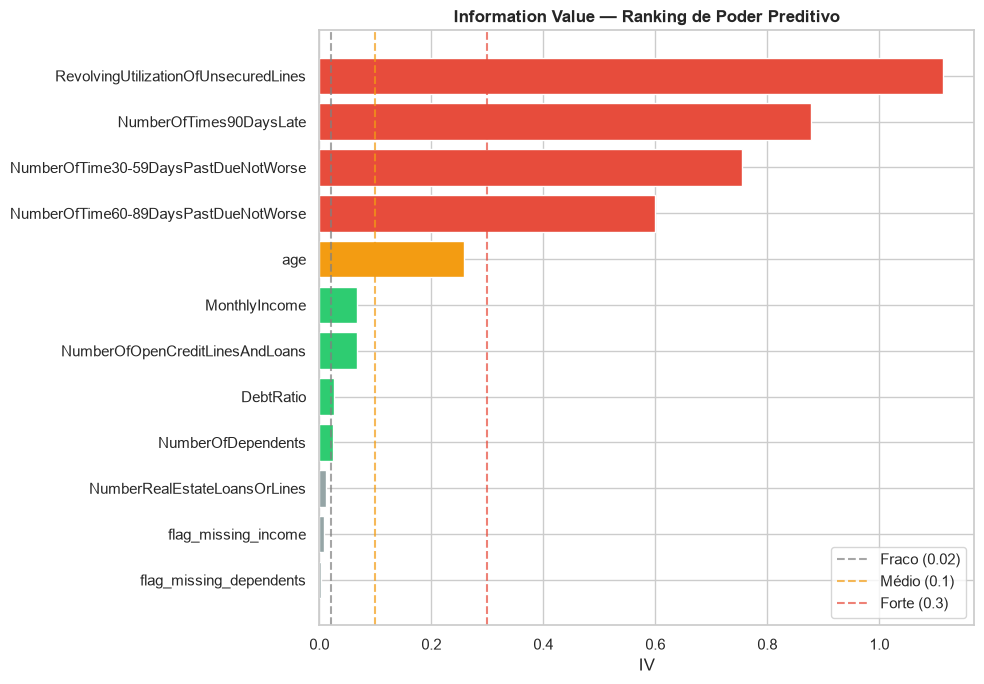

In [46]:
# CONSOLIDANDO OS RESULTADOS DE IV
iv_final = {
    "RevolvingUtilizationOfUnsecuredLines": 1.1134,
    "NumberOfTimes90DaysLate": 0.8774,
    "NumberOfTime30-59DaysPastDueNotWorse": 0.7552,
    "NumberOfTime60-89DaysPastDueNotWorse": 0.6000,
    "age": 0.2592,
    "MonthlyIncome": 0.0670,
    "NumberOfOpenCreditLinesAndLoans": 0.0669,
    "DebtRatio": 0.0253,
    "NumberOfDependents": 0.0250,
    "NumberRealEstateLoansOrLines": 0.0121,
    "flag_missing_income": 0.0077,
    "flag_missing_dependents": 0.0037
}

iv_final_df = pd.DataFrame.from_dict(
    iv_final, orient="index", columns=["IV"]
).sort_values("IV", ascending=True)

# Visualização
fig, ax = plt.subplots(figsize=(10, 7))
cores = ["#e74c3c" if v > 0.3 else "#f39c12" if v > 0.1
         else "#2ecc71" if v > 0.02 else "#95a5a6"
         for v in iv_final_df["IV"]]
ax.barh(iv_final_df.index, iv_final_df["IV"], color=cores)
ax.axvline(0.02, color="gray", linestyle="--", alpha=0.7, label="Fraco (0.02)")
ax.axvline(0.1, color="#f39c12", linestyle="--", alpha=0.7, label="Médio (0.1)")
ax.axvline(0.3, color="#e74c3c", linestyle="--", alpha=0.7, label="Forte (0.3)")
ax.set_title("Information Value — Ranking de Poder Preditivo", fontweight="bold")
ax.set_xlabel("IV")
ax.legend()
plt.tight_layout()
plt.savefig("../../reports/iv_ranking.png", dpi=150, bbox_inches="tight")
plt.show()

In [47]:
# SALVANDO O DATASET LIMPO
df.to_csv("../../data/processed/credit_processed.csv", index=False)
print(f"Dataset salvo: {df.shape}")

Dataset salvo: (149999, 13)


In [48]:
# RESUMO DA EDA
decisoes = {
    "registros_originais": 150000,
    "registros_finais": len(df),
    "registros_removidos": 150000 - len(df),
    "features_originais": 11,
    "features_criadas": ["flag_missing_income", "flag_missing_dependents"],
    "tratamentos_aplicados": [
        "Removido 1 registro com age=0 (dado inválido)",
        "Winsorização RevolvingUtilization no p99",
        "Winsorização MonthlyIncome no p99",
        "Winsorização DebtRatio no p99 do grupo plausível (DebtRatio < 2)",
        "Imputação MonthlyIncome com mediana (19.8% missing)",
        "Imputação NumberOfDependents com mediana (2.6% missing)",
        "Criação de flags de missing antes da imputação"
    ],
    "achados_criticos": [
        "DebtRatio corrompido para 93% dos clientes sem renda informada",
        "Features de atraso com 94%+ de zeros — IV calculado com bins de negócio",
        "RevolvingUtilization com IV=1.11 investigado e confirmado como legítimo",
        "Relação monotônica entre idade e inadimplência confirmada",
        "Um único atraso de 90 dias já eleva drasticamente o risco"
    ]
}

import json
with open("../../reports/eda_decisions.json", "w", encoding="utf-8") as f:
    json.dump(decisoes, f, ensure_ascii=False, indent=2)

print("\n=== RESUMO FINAL DA EDA ===")
for k, v in decisoes.items():
    print(f"\n{k}:")
    if isinstance(v, list):
        for item in v:
            print(f"  • {item}")
    else:
        print(f"  {v}")


=== RESUMO FINAL DA EDA ===

registros_originais:
  150000

registros_finais:
  149999

registros_removidos:
  1

features_originais:
  11

features_criadas:
  • flag_missing_income
  • flag_missing_dependents

tratamentos_aplicados:
  • Removido 1 registro com age=0 (dado inválido)
  • Winsorização RevolvingUtilization no p99
  • Winsorização MonthlyIncome no p99
  • Winsorização DebtRatio no p99 do grupo plausível (DebtRatio < 2)
  • Imputação MonthlyIncome com mediana (19.8% missing)
  • Imputação NumberOfDependents com mediana (2.6% missing)
  • Criação de flags de missing antes da imputação

achados_criticos:
  • DebtRatio corrompido para 93% dos clientes sem renda informada
  • Features de atraso com 94%+ de zeros — IV calculado com bins de negócio
  • RevolvingUtilization com IV=1.11 investigado e confirmado como legítimo
  • Relação monotônica entre idade e inadimplência confirmada
  • Um único atraso de 90 dias já eleva drasticamente o risco
